# 03 — Q2: Dự đoán điểm chất lượng trước khi cupping (ML)

**Người phụ trách:** Ngọc Hoàng · **Yêu cầu ML 1–6** · **Loại:** ML (hồi quy) · Nguồn: `docs/questions.md`

> PHẦN 1 Định nghĩa bài toán · PHẦN 2 Chia dữ liệu theo thời gian · PHẦN 3 Pipeline, baseline, CV · PHẦN 4 Tinh chỉnh bằng CV · PHẦN 5 Đánh giá test (một lần) · PHẦN 6 Phân tích lỗi · PHẦN 7 Diễn giải và trả lời câu hỏi.

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 0</span>

## <span style="color:#ffffff">Môi trường code &amp; thư viện</span>

<span style="font-size:15px;color:#DCE6F7">Kiểm tra kernel và phiên bản thư viện khớp với <b>environment.yml</b></span>

</div>

In [1]:
import sys
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NOTEBOOK_CWD = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_CWD.parent if NOTEBOOK_CWD.name == "notebooks" else NOTEBOOK_CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RANDOM_STATE, SCORE_COLS
from src.cleaning import load_raw, convert_types, flag_placeholders
from src.features import add_total_score, add_grading_date
from src.labels import normalize_labels

pd.set_option("display.max_columns", None)

%matplotlib inline

print("python      :", sys.executable)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

python      : /home/hoang/miniconda3/envs/coffee/bin/python
numpy       : 1.26.4
pandas      : 2.1.4
matplotlib  : 3.8.4
scikit-learn: 1.9.1


<span style="color:#5B6B8C;font-size:14px">→ Mong đợi: đường dẫn kết thúc bằng <code>.../envs/coffee/bin/python</code></span>

In [2]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
assert major_minor(sklearn.__version__) == "1.9", f"scikit-learn {sklearn.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 1</span>

## <span style="color:#ffffff">Problem definition</span>

<span style="font-size:15px;color:#DCE6F7">Câu hỏi, đối tượng sử dụng, làm sạch theo phạm vi chung và chặn rò rỉ dữ liệu</span>

</div>

### <span style="color:#283E75">▍Câu hỏi Q2 (trích nguyên văn <code>docs/questions.md</code>)</span>

**Câu hỏi:** Khi nhận mẫu cà phê nhân xanh, chỉ dựa trên thông tin có sẵn **trước khi cupping** (xuất xứ, giống, phương pháp sơ chế, màu hạt, độ ẩm, số lỗi hạt, năm thu hoạch), mô hình dự đoán `total_9` sai lệch trung bình bao nhiêu điểm, có tốt hơn đáng kể so với việc chỉ đoán điểm trung bình không, và thông tin nào giúp dự đoán nhiều nhất?

- **Motivation:** nhà nhập khẩu nhận nhiều mẫu nhưng cupping tốn thời gian và chi phí; điểm dự đoán giúp **ưu tiên lô nào gửi đi chấm trước** và ước lượng sơ bộ chất lượng khi đàm phán.

✍️ **TODO (Hoàng tự viết):** ai dùng, lúc nào, quyết định gì

### <span style="color:#283E75">▍Đọc và làm sạch theo phạm vi chung</span>

1. Đọc dữ liệu → `convert_types` → `normalize_labels` → `add_total_score` → `add_grading_date`.
2. Chỉ giữ Arabica.
3. Bỏ bản ghi giữ chỗ `flag_placeholders(...)["zero_all_scores"]` (`REC_ID = 1310`).
4. Bỏ dòng thiếu `total_9`.
5. Thay `Moisture = 0` bằng NaN (không bỏ dòng; Pipeline sẽ điền thiếu, chỉ học từ train).

In [3]:
TARGET = "total_9"
SPLIT_DATE = pd.Timestamp("2016-01-01")

row_counts = {}   # Bước -> số lô còn lại

df = add_grading_date(add_total_score(normalize_labels(convert_types(load_raw()))))
row_counts["1. Dữ liệu gốc (load → convert → normalize → total_9 → grading_date)"] = len(df)
print(f"Số lô: {len(df):,} · số cột: {df.shape[1]}")

Số lô: 1,339 · số cột: 24


<span style="color:#5B6B8C;font-size:14px"><code>normalize_labels</code> đưa nhãn về chữ thường → in nhãn thực tế trước khi lọc.</span>

In [4]:
print(df["Species"].value_counts(dropna=False))

Species
arabica    1311
robusta      28
Name: count, dtype: Int64


In [5]:
ARABICA = "arabica"   # đúng chuỗi in ra ở ô trên
assert ARABICA in set(df["Species"].dropna()), f"Không tìm thấy nhãn {ARABICA!r} trong Species"

df_ml = df[df["Species"].eq(ARABICA)].copy()
row_counts["2. Chỉ giữ Arabica"] = len(df_ml)

placeholder = flag_placeholders(df_ml)["zero_all_scores"]
print("REC_ID bị đánh dấu zero_all_scores:", df_ml.loc[placeholder, "REC_ID"].tolist())
df_ml = df_ml[~placeholder].copy()
row_counts["3. Bỏ bản ghi giữ chỗ (zero_all_scores)"] = len(df_ml)

print("Số dòng thiếu total_9:", df_ml[TARGET].isna().sum())
df_ml = df_ml.dropna(subset=[TARGET]).copy()
row_counts["4. Bỏ dòng thiếu total_9"] = len(df_ml)

n_zero_moisture = int(df_ml["Moisture"].eq(0).sum())
df_ml["Moisture"] = df_ml["Moisture"].mask(df_ml["Moisture"].eq(0))
row_counts["5. Moisture = 0 → NaN (không lọc)"] = len(df_ml)
print(f"Số lô Moisture = 0 đổi thành NaN: {n_zero_moisture}")

clean_steps = pd.DataFrame(list(row_counts.items()), columns=["Bước", "Số lô"])
clean_steps["Lý do"] = [
    "Dữ liệu gốc",
    "Phạm vi chung của nhóm: chỉ Arabica (docs/questions.md)",
    "REC_ID 1310: cả 9 điểm = 0, bản ghi giữ chỗ",
    "Không có biến mục tiêu",
    "Moisture = 0 là giá trị thiếu (EDA 3.2.2); không bỏ dòng, Pipeline điền median từ train",
]
display(clean_steps)

REC_ID bị đánh dấu zero_all_scores: [1310]
Số dòng thiếu total_9: 0
Số lô Moisture = 0 đổi thành NaN: 252


,Bước,Số lô,Lý do
0,1. Dữ liệu gốc (load → convert → normalize → t...,1339,Dữ liệu gốc
1,2. Chỉ giữ Arabica,1311,Phạm vi chung của nhóm: chỉ Arabica (docs/ques...
2,3. Bỏ bản ghi giữ chỗ (zero_all_scores),1310,"REC_ID 1310: cả 9 điểm = 0, bản ghi giữ chỗ"
3,4. Bỏ dòng thiếu total_9,1310,Không có biến mục tiêu
4,5. Moisture = 0 → NaN (không lọc),1310,Moisture = 0 là giá trị thiếu (EDA 3.2.2); khô...


### <span style="color:#283E75">▍Feature được dùng</span>

<span style="color:#5B6B8C;font-size:14px">Chỉ gồm thông tin có trước khi cupping. Thống kê dưới đây chỉ để mô tả, <b>không</b> dùng để biến đổi dữ liệu.</span>

In [6]:
NUM_FEATURES = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects", "Harvest.Year"]
CAT_FEATURES = ["Country.of.Origin", "Continent.of.Origin", "Variety", "Processing.Method", "Color"]
FEATURES = CAT_FEATURES + NUM_FEATURES

feature_table = pd.DataFrame({
    "Cột": FEATURES,
    "Kiểu": ["phân loại" if c in CAT_FEATURES else "số" for c in FEATURES],
    "Số giá trị thiếu": [int(df_ml[c].isna().sum()) for c in FEATURES],
    "% thiếu": [round(df_ml[c].isna().mean() * 100, 1) for c in FEATURES],
    "Số giá trị khác nhau": [int(df_ml[c].nunique(dropna=True)) for c in FEATURES],
})
display(feature_table)

,Cột,Kiểu,Số giá trị thiếu,% thiếu,Số giá trị khác nhau
0,Country.of.Origin,phân loại,1,0.1,34
1,Continent.of.Origin,phân loại,1,0.1,5
2,Variety,phân loại,201,15.3,29
3,Processing.Method,phân loại,151,11.5,5
4,Color,phân loại,216,16.5,4
5,Moisture,số,252,19.2,22
6,Quakers,số,0,0.0,11
7,Category.One.Defects,số,0,0.0,16
8,Category.Two.Defects,số,0,0.0,38
9,Harvest.Year,số,60,4.6,10


<span style="color:#5B6B8C;font-size:14px">Số nhóm có &lt; 20 lô ở mỗi cột phân loại (trên toàn mẫu sạch, chỉ để mô tả; việc gộp nhóm hiếm thực sự do <code>OneHotEncoder(min_frequency=20)</code> học trên train).</span>

In [7]:
rare_table = pd.DataFrame({
    "Cột": CAT_FEATURES,
    "Số nhóm": [df_ml[c].nunique() for c in CAT_FEATURES],
    "Số nhóm < 20 lô": [int(df_ml[c].value_counts().lt(20).sum()) for c in CAT_FEATURES],
    "Số lô thuộc nhóm < 20 lô": [
        int(df_ml[c].value_counts().loc[lambda s: s.lt(20)].sum()) for c in CAT_FEATURES
    ],
})
display(rare_table)

,Cột,Số nhóm,Số nhóm < 20 lô,Số lô thuộc nhóm < 20 lô
0,Country.of.Origin,34,18,80
1,Continent.of.Origin,5,1,1
2,Variety,29,20,103
3,Processing.Method,5,1,14
4,Color,4,0,0


### <span style="color:#283E75">▍Cột bị loại và lý do</span>

In [8]:
DROPPED = (
    [(c, "Thuộc tính cảm quan; 9 cột cộng lại chính là total_9") for c in SCORE_COLS]
    + [
        (TARGET, "Biến mục tiêu"),
        ("REC_ID", "Định danh bản ghi"),
        ("Expiration", "Chỉ biết sau khi chấm; chỉ dùng để chia dữ liệu"),
        ("grading_date", "Suy ra từ Expiration; chỉ dùng để chia dữ liệu"),
        ("Species", "Đã lọc chỉ còn một giá trị (arabica)"),
    ]
)
DROPPED_COLS = [c for c, _ in DROPPED]
dropped_table = pd.DataFrame(DROPPED, columns=["Cột", "Lý do loại"])
display(dropped_table)

unaccounted = sorted(set(df_ml.columns) - set(FEATURES) - set(DROPPED_COLS))
assert not unaccounted, f"Có cột chưa được xếp vào feature hay cột bị loại: {unaccounted}"
assert not set(FEATURES) & set(DROPPED_COLS), "Một cột vừa là feature vừa bị loại"

,Cột,Lý do loại
0,Aroma,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
1,Flavor,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
2,Aftertaste,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
3,Acidity,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
4,Body,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
5,Balance,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
6,Uniformity,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
7,Clean.Cup,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
8,Sweetness,Thuộc tính cảm quan; 9 cột cộng lại chính là t...
9,total_9,Biến mục tiêu


✍️ **TODO (Hoàng tự viết):** giải thích vì sao các cột trên gây rò rỉ dữ liệu

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 2</span>

## <span style="color:#ffffff">Split theo thời gian</span>

<span style="font-size:15px;color:#DCE6F7">Train = lô chấm trước 2016-01-01, test = từ mốc trở đi</span>

</div>

In [9]:
df_ml = df_ml.sort_values(["grading_date", "REC_ID"], kind="mergesort").reset_index(drop=True)
assert df_ml["grading_date"].notna().all(), "Có lô thiếu grading_date"

is_train = df_ml["grading_date"].lt(SPLIT_DATE)
train_df = df_ml[is_train].copy()
test_df = df_ml[~is_train].copy()


def describe_set(name, part):
    return {
        "Tập": name,
        "Số lô": len(part),
        "Ngày chấm sớm nhất": part["grading_date"].min().date(),
        "Ngày chấm muộn nhất": part["grading_date"].max().date(),
        "Mean total_9": part[TARGET].mean(),
        "Std total_9": part[TARGET].std(),
        "Median total_9": part[TARGET].median(),
    }


split_table = pd.DataFrame([describe_set("Train", train_df), describe_set("Test", test_df)])
display(split_table.round(2))

,Tập,Số lô,Ngày chấm sớm nhất,Ngày chấm muộn nhất,Mean total_9,Std total_9,Median total_9
0,Train,1041,2010-04-09,2015-12-28,74.60,2.47,74.92
1,Test,269,2016-01-12,2018-01-19,74.96,1.98,75.25


#### <span style="color:#3B5BA9">Kiểm tra cặp trùng <code>REC_ID</code> 721 / 742</span>

In [10]:
pair = df_ml.loc[df_ml["REC_ID"].isin([721, 742]), ["REC_ID", "grading_date"]].assign(
    Tập=lambda d: np.where(d["grading_date"].lt(SPLIT_DATE), "Train", "Test")
)
display(pair)
assert len(pair) == 2, f"Phải có đủ 2 bản ghi 721 / 742, đang có {len(pair)}"
assert pair["Tập"].nunique() == 1, "REC_ID 721 và 742 rơi vào 2 tập khác nhau — DỪNG LẠI và báo nhóm"
print("721 / 742 cùng nằm trong tập:", pair["Tập"].iloc[0])

,REC_ID,grading_date,Tập
579,721,2013-12-26,Train
580,742,2013-12-26,Train


721 / 742 cùng nằm trong tập: Train


> ⚠️ **Tập test chỉ được đánh giá một lần ở PHẦN 5.** Từ sau ô dưới đây đến ô gắn tag `test-eval` (ô đầu tiên của PHẦN 5), không ô nào được đọc `X_test` / `y_test`.

In [11]:
# Tách X / y. X chỉ gồm FEATURES; đổi kiểu (không học gì từ dữ liệu) để sklearn xử lý NaN thống nhất:
#   cột phân loại: pandas string (pd.NA) → object (np.nan); cột số: Int64 → float.
def to_model_frame(part):
    X = part[FEATURES].copy()
    for c in CAT_FEATURES:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    for c in NUM_FEATURES:
        X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)
    return X


X_train, y_train = to_model_frame(train_df), train_df[TARGET].to_numpy()
X_test, y_test = to_model_frame(test_df), test_df[TARGET].to_numpy()   # cất đi, chỉ dùng ở tuần 3
print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")

X_train: (1041, 10) · X_test: (269, 10)


#### <span style="color:#3B5BA9">Số lô train / test theo năm chấm</span>

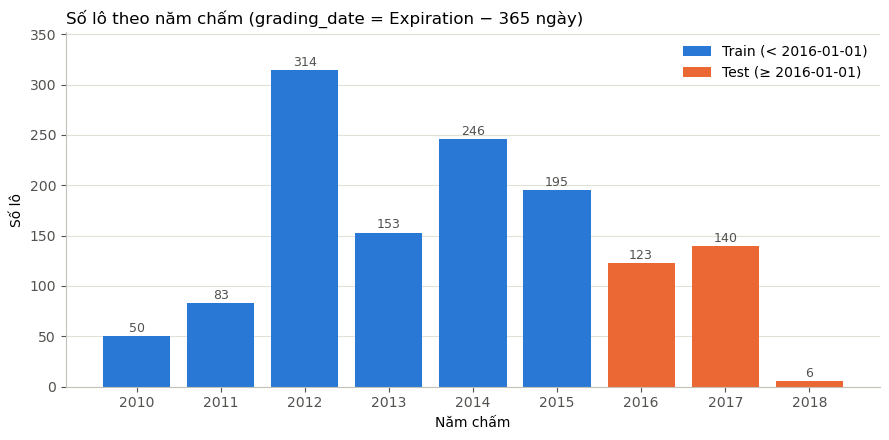

In [12]:
COLOR_TRAIN = "#2a78d6"
COLOR_TEST = "#eb6834"
INK_SECONDARY = "#52514e"
GRID_COLOR = "#e1e0d9"


def style_axes(ax, grid_axis="y"):
    """Lưới mảnh, bỏ viền trên/phải."""
    ax.grid(axis=grid_axis, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=INK_SECONDARY)


year_counts = (
    df_ml.assign(Năm=df_ml["grading_date"].dt.year,
                 Tập=np.where(is_train, "Train", "Test"))
    .groupby(["Năm", "Tập"]).size().unstack("Tập", fill_value=0)
    .reindex(columns=["Train", "Test"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
years = year_counts.index.astype(str)
ax.bar(years, year_counts["Train"], color=COLOR_TRAIN, label=f"Train (< {SPLIT_DATE.date()})")
ax.bar(years, year_counts["Test"], bottom=year_counts["Train"], color=COLOR_TEST,
       label=f"Test (≥ {SPLIT_DATE.date()})")
for x, total in zip(years, year_counts.sum(axis=1)):
    ax.annotate(f"{total}", (x, total), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=9, color=INK_SECONDARY)
ax.set_ylim(0, year_counts.sum(axis=1).max() * 1.12)
ax.set_title("Số lô theo năm chấm (grading_date = Expiration − 365 ngày)", loc="left", fontsize=12)
ax.set_xlabel("Năm chấm")
ax.set_ylabel("Số lô")
ax.legend(frameon=False)
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** vì sao chia theo thời gian thay vì ngẫu nhiên

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 3</span>

## <span style="color:#ffffff">Pipeline, baseline và 2 mô hình</span>

<span style="font-size:15px;color:#DCE6F7">Mọi bước học từ dữ liệu nằm trong Pipeline · cross-validation chỉ trên train</span>

</div>

### <span style="color:#283E75">▍Tiền xử lý trong <code>ColumnTransformer</code></span>

In [13]:
def make_preprocessor(num_features=NUM_FEATURES, cat_features=CAT_FEATURES):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", numeric, num_features),
        ("cat", categorical, cat_features),
    ])


MODELS = {
    "Baseline (Dummy mean)": DummyRegressor(strategy="mean"),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}
pipelines = {name: Pipeline([("pre", make_preprocessor()), ("reg", model)])
             for name, model in MODELS.items()}
pipelines["Ridge (alpha=1.0)"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of 

### <span style="color:#283E75">▍Cross-validation <code>TimeSeriesSplit(n_splits=5)</code> trên train</span>

<span style="color:#5B6B8C;font-size:14px"><code>X_train</code> đã sắp theo <code>grading_date</code> nên mỗi fold validation luôn nằm sau phần dữ liệu dùng để fit. MAE/RMSE đơn vị điểm <code>total_9</code>; sklearn trả về giá trị âm nên đổi dấu khi báo cáo.</span>

In [14]:
tscv = TimeSeriesSplit(n_splits=5)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

cv_results = {}
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=SCORING)
    cv_results[name] = {"MAE": -res["test_MAE"], "RMSE": -res["test_RMSE"]}

fold_sizes = pd.DataFrame(
    [{"Fold": k + 1, "Số lô fit": len(tr), "Số lô validation": len(va),
      "Validation từ": train_df["grading_date"].iloc[va[0]].date(),
      "Validation đến": train_df["grading_date"].iloc[va[-1]].date()}
     for k, (tr, va) in enumerate(tscv.split(X_train))]
)
display(fold_sizes)

,Fold,Số lô fit,Số lô validation,Validation từ,Validation đến
0,1,176,173,2012-02-23,2012-08-30
1,2,349,173,2012-08-30,2013-05-30
2,3,522,173,2013-05-30,2014-05-05
3,4,695,173,2014-05-05,2015-02-13
4,5,868,173,2015-02-15,2015-12-28


In [15]:
baseline_mae = cv_results["Baseline (Dummy mean)"]["MAE"].mean()
cv_table = pd.DataFrame([
    {
        "Mô hình": name,
        "MAE (điểm)": f"{r['MAE'].mean():.3f} ± {r['MAE'].std():.3f}",
        "RMSE (điểm)": f"{r['RMSE'].mean():.3f} ± {r['RMSE'].std():.3f}",
        "MAE so với baseline (điểm)": round(r["MAE"].mean() - baseline_mae, 3),
        "MAE so với baseline (%)": round((r["MAE"].mean() / baseline_mae - 1) * 100, 1),
    }
    for name, r in cv_results.items()
])
display(cv_table)

,Mô hình,MAE (điểm),RMSE (điểm),MAE so với baseline (điểm),MAE so với baseline (%)
0,Baseline (Dummy mean),1.654 ± 0.118,2.524 ± 0.306,0.000,0.0
1,Ridge (alpha=1.0),1.772 ± 0.140,2.432 ± 0.248,0.118,7.1
2,Random Forest,1.725 ± 0.125,2.527 ± 0.251,0.070,4.2


<span style="color:#5B6B8C;font-size:14px">± là độ lệch chuẩn qua 5 fold. Cột “so với baseline” &lt; 0 nghĩa là sai số nhỏ hơn baseline.</span>

#### <span style="color:#3B5BA9">MAE từng fold</span>

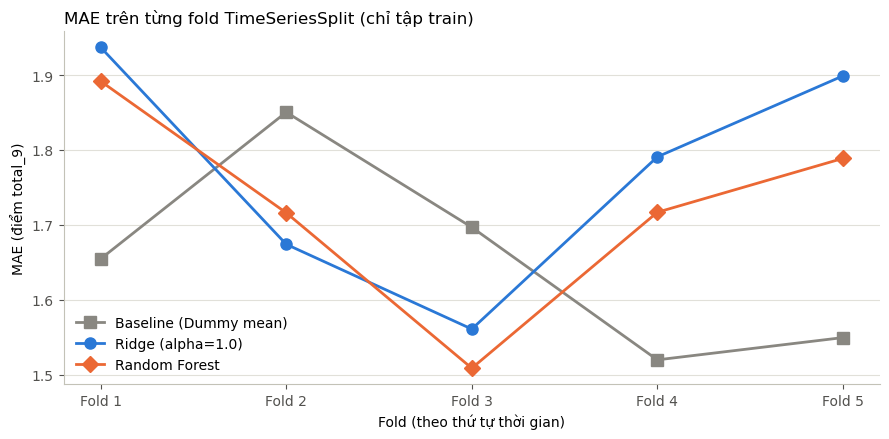

In [16]:
MODEL_COLORS = {
    "Baseline (Dummy mean)": "#898781",
    "Ridge (alpha=1.0)": "#2a78d6",
    "Random Forest": "#eb6834",
}
MODEL_MARKERS = {"Baseline (Dummy mean)": "s", "Ridge (alpha=1.0)": "o", "Random Forest": "D"}

fig, ax = plt.subplots(figsize=(9, 4.5))
folds = np.arange(1, tscv.get_n_splits() + 1)
for name, r in cv_results.items():
    ax.plot(folds, r["MAE"], marker=MODEL_MARKERS[name], markersize=8, linewidth=2,
            color=MODEL_COLORS[name], label=name)
ax.set_xticks(folds)
ax.set_xticklabels([f"Fold {k}" for k in folds])
ax.set_title("MAE trên từng fold TimeSeriesSplit (chỉ tập train)", loc="left", fontsize=12)
ax.set_xlabel("Fold (theo thứ tự thời gian)")
ax.set_ylabel("MAE (điểm total_9)")
ax.legend(frameon=False)
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** nhận xét CV — mô hình nào hơn baseline, hơn bao nhiêu điểm

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 4</span>

## <span style="color:#ffffff">Tinh chỉnh bằng cross-validation</span>

<span style="font-size:15px;color:#DCE6F7">GridSearchCV với TimeSeriesSplit(5) trên train; chọn mô hình trước khi chạm tập test</span>

</div>

### <span style="color:#283E75">▍4a · Chọn metric</span>

✍️ **TODO (Hoàng tự viết):** lý do chọn MAE làm metric chính (đơn vị điểm, gắn với quyết định của nhà nhập khẩu), RMSE phụ để thấy lỗi lớn; vì sao không dùng R² làm metric chính.

### <span style="color:#283E75">▍4b · Baseline median</span>

<span style="color:#5B6B8C;font-size:14px">Cùng <code>tscv</code> và <code>SCORING</code> như PHẦN 3. Đơn vị MAE/RMSE: điểm <code>total_9</code>.</span>

In [17]:
pipe_baseline_median = Pipeline([("pre", make_preprocessor()), ("reg", DummyRegressor(strategy="median"))])
res = cross_validate(pipe_baseline_median, X_train, y_train, cv=tscv, scoring=SCORING)
cv_baseline_median = {"MAE": -res["test_MAE"], "RMSE": -res["test_RMSE"]}
print(f"Baseline median · MAE CV = {cv_baseline_median['MAE'].mean():.3f} ± {cv_baseline_median['MAE'].std():.3f} điểm")

Baseline median · MAE CV = 1.654 ± 0.163 điểm


### <span style="color:#283E75">▍4c · <code>GridSearchCV</code> cho Ridge và Random Forest, 2 biến thể feature</span>

<span style="color:#5B6B8C;font-size:14px">Biến thể A: đủ 10 feature · Biến thể B: bỏ <code>Harvest.Year</code>. Mỗi biến thể dùng <code>make_preprocessor(num_features=...)</code> tương ứng và chỉ đưa đúng các cột đó vào <code>fit</code>. Chỉ fit trên train.</span>

In [18]:
FEATURE_VARIANTS = {
    "A (đủ 10 feature)": NUM_FEATURES,
    "B (bỏ Harvest.Year)": [c for c in NUM_FEATURES if c != "Harvest.Year"],
}
PARAM_GRIDS = {
    "Ridge": (Ridge(), {"reg__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE),
        {"reg__n_estimators": [200, 500], "reg__max_depth": [4, 8, None], "reg__min_samples_leaf": [5, 20, 50]},
    ),
}

grids = {}              # (họ mô hình, biến thể) -> GridSearchCV đã fit
variant_features = {}   # biến thể -> danh sách cột đưa vào mô hình
fit_rows = {}           # (họ mô hình, biến thể) -> số dòng dùng để fit
for variant, num_cols in FEATURE_VARIANTS.items():
    cols = CAT_FEATURES + num_cols
    variant_features[variant] = cols
    X_variant = X_train[cols]
    for family, (estimator, grid) in PARAM_GRIDS.items():
        pipe = Pipeline([("pre", make_preprocessor(num_features=num_cols)), ("reg", clone(estimator))])
        search = GridSearchCV(pipe, grid, cv=tscv, scoring=SCORING, refit="MAE", n_jobs=-1)
        search.fit(X_variant, y_train)
        grids[(family, variant)] = search
        fit_rows[(family, variant)] = len(X_variant)
        print(f"{family:<13} · {variant:<20} · {len(search.cv_results_['params']):>2} cấu hình · "
              f"MAE CV tốt nhất = {-search.best_score_:.3f} điểm")

Ridge         · A (đủ 10 feature)    ·  6 cấu hình · MAE CV tốt nhất = 1.599 điểm


Random Forest · A (đủ 10 feature)    · 18 cấu hình · MAE CV tốt nhất = 1.566 điểm
Ridge         · B (bỏ Harvest.Year)  ·  6 cấu hình · MAE CV tốt nhất = 1.538 điểm


Random Forest · B (bỏ Harvest.Year)  · 18 cấu hình · MAE CV tốt nhất = 1.561 điểm


### <span style="color:#283E75">▍4d · Bảng kết quả CV (cấu hình tốt nhất của mỗi mô hình)</span>

<span style="color:#5B6B8C;font-size:14px">Đơn vị: điểm <code>total_9</code>. mean ± std qua 5 fold, lấy từ <code>cv_results_</code> của cấu hình tốt nhất. Cột “so với baseline” &lt; 0 nghĩa là MAE nhỏ hơn baseline.</span>

In [19]:
baseline_mean_mae = cv_results["Baseline (Dummy mean)"]["MAE"].mean()
baseline_median_mae = cv_baseline_median["MAE"].mean()


def cv_row(model, variant, params, mae, mae_std, rmse, rmse_std):
    return {
        "Mô hình": model, "Biến thể feature": variant, "Tham số tốt nhất": params,
        "MAE mean": mae, "MAE std": mae_std, "RMSE mean": rmse, "RMSE std": rmse_std,
    }


rows = [
    cv_row("Baseline mean", "—", "—", baseline_mean_mae, cv_results["Baseline (Dummy mean)"]["MAE"].std(),
           cv_results["Baseline (Dummy mean)"]["RMSE"].mean(), cv_results["Baseline (Dummy mean)"]["RMSE"].std()),
    cv_row("Baseline median", "—", "—", baseline_median_mae, cv_baseline_median["MAE"].std(),
           cv_baseline_median["RMSE"].mean(), cv_baseline_median["RMSE"].std()),
]
for family in PARAM_GRIDS:
    for variant in FEATURE_VARIANTS:
        search = grids[(family, variant)]
        k, res = search.best_index_, search.cv_results_
        params = ", ".join(f"{p.replace('reg__', '')}={v}" for p, v in search.best_params_.items())
        rows.append(cv_row(family, variant, params,
                           -res["mean_test_MAE"][k], res["std_test_MAE"][k],
                           -res["mean_test_RMSE"][k], res["std_test_RMSE"][k]))

cv_summary = pd.DataFrame(rows)
cv_summary["MAE so với baseline mean"] = cv_summary["MAE mean"] - baseline_mean_mae
cv_summary["MAE so với baseline median"] = cv_summary["MAE mean"] - baseline_median_mae

cv_display = pd.DataFrame({
    "Mô hình": cv_summary["Mô hình"],
    "Biến thể feature": cv_summary["Biến thể feature"],
    "Tham số tốt nhất": cv_summary["Tham số tốt nhất"],
    "MAE CV (điểm)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(cv_summary["MAE mean"], cv_summary["MAE std"])],
    "RMSE CV (điểm)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(cv_summary["RMSE mean"], cv_summary["RMSE std"])],
    "MAE so với baseline mean (điểm)": cv_summary["MAE so với baseline mean"].round(3),
    "MAE so với baseline median (điểm)": cv_summary["MAE so với baseline median"].round(3),
})
display(cv_display)

,Mô hình,Biến thể feature,Tham số tốt nhất,MAE CV (điểm),RMSE CV (điểm),MAE so với baseline mean (điểm),MAE so với baseline median (điểm)
0,Baseline mean,—,—,1.654 ± 0.118,2.524 ± 0.306,0.000,0.000
1,Baseline median,—,—,1.654 ± 0.163,2.558 ± 0.375,-0.000,0.000
2,Ridge,A (đủ 10 feature),alpha=1000,1.599 ± 0.073,2.426 ± 0.269,-0.055,-0.055
3,Ridge,B (bỏ Harvest.Year),alpha=100,1.538 ± 0.046,2.323 ± 0.277,-0.116,-0.116
4,Random Forest,A (đủ 10 feature),"max_depth=4, min_samples_leaf=50, n_estimators...",1.566 ± 0.050,2.387 ± 0.333,-0.088,-0.088
5,Random Forest,B (bỏ Harvest.Year),"max_depth=4, min_samples_leaf=50, n_estimators...",1.561 ± 0.059,2.379 ± 0.345,-0.094,-0.093


### <span style="color:#283E75">▍4e · Chọn cấu hình cuối (chỉ dựa trên CV)</span>

In [20]:
final_models, final_features, final_variant, final_cv_mae = {}, {}, {}, {}
for family in PARAM_GRIDS:
    # best_score_ = −MAE CV của cấu hình tốt nhất → lớn hơn là tốt hơn
    variant = max(FEATURE_VARIANTS, key=lambda v: grids[(family, v)].best_score_)
    final_models[family] = grids[(family, variant)].best_estimator_   # đã refit trên toàn train
    final_features[family] = variant_features[variant]
    final_variant[family] = variant
    final_cv_mae[family] = -grids[(family, variant)].best_score_
    print(f"{family:<13} → biến thể {variant}, {grids[(family, variant)].best_params_} · "
          f"MAE CV = {final_cv_mae[family]:.3f} điểm")

BEST_NAME = min(final_cv_mae, key=final_cv_mae.get)
print(f"\nBEST_NAME = {BEST_NAME!r} (MAE CV thấp nhất: {final_cv_mae[BEST_NAME]:.3f} điểm; "
      f"baseline mean {baseline_mean_mae:.3f} điểm)")

Ridge         → biến thể B (bỏ Harvest.Year), {'reg__alpha': 100} · MAE CV = 1.538 điểm
Random Forest → biến thể B (bỏ Harvest.Year), {'reg__max_depth': 4, 'reg__min_samples_leaf': 50, 'reg__n_estimators': 200} · MAE CV = 1.561 điểm

BEST_NAME = 'Ridge' (MAE CV thấp nhất: 1.538 điểm; baseline mean 1.654 điểm)


#### <span style="color:#3B5BA9">MAE CV của 6 cấu hình</span>

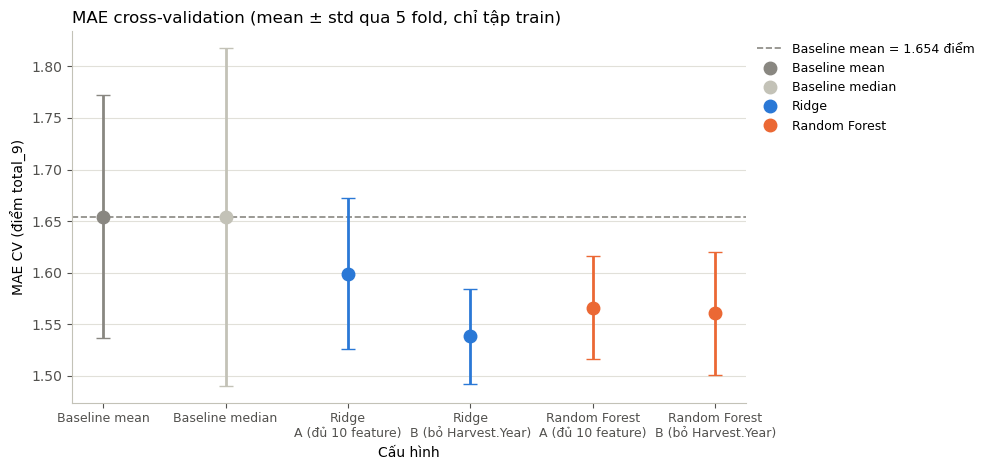

In [21]:
FAMILY_COLORS = {
    "Baseline mean": MODEL_COLORS["Baseline (Dummy mean)"],
    "Baseline median": "#c3c2b7",
    "Ridge": MODEL_COLORS["Ridge (alpha=1.0)"],
    "Random Forest": MODEL_COLORS["Random Forest"],
}

fig, ax = plt.subplots(figsize=(10, 4.8))
x_pos = np.arange(len(cv_summary))
for x, row in zip(x_pos, cv_summary.itertuples(index=False)):
    ax.errorbar(x, row[3], yerr=row[4], fmt="o", markersize=9, capsize=5, elinewidth=2,
                color=FAMILY_COLORS[row[0]], zorder=3)
ax.axhline(baseline_mean_mae, color=FAMILY_COLORS["Baseline mean"], linestyle="--", linewidth=1.2,
           label=f"Baseline mean = {baseline_mean_mae:.3f} điểm", zorder=1)
for family, color in FAMILY_COLORS.items():
    ax.plot([], [], "o", color=color, markersize=9, label=family)
ax.set_xticks(x_pos)
ax.set_xticklabels([m if v == "—" else f"{m}\n{v}" for m, v in zip(cv_summary["Mô hình"], cv_summary["Biến thể feature"])],
                   fontsize=9)
ax.set_title("MAE cross-validation (mean ± std qua 5 fold, chỉ tập train)", loc="left", fontsize=12)
ax.set_xlabel("Cấu hình")
ax.set_ylabel("MAE CV (điểm total_9)")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** nhận xét tinh chỉnh — tham số tốt nhất, bỏ Harvest.Year có giúp không, mô hình nào được chọn và vì sao (theo CV).

In [22]:
# TEST
assert all(search.n_splits_ == 5 for search in grids.values()), "Mọi GridSearchCV phải dùng 5 fold"
assert len(grids) == len(PARAM_GRIDS) * len(FEATURE_VARIANTS) == 4, f"Phải có 4 GridSearchCV, đang có {len(grids)}"
assert set(final_models) == set(PARAM_GRIDS), f"final_models phải có {list(PARAM_GRIDS)}"
assert BEST_NAME in final_models, f"BEST_NAME {BEST_NAME!r} không nằm trong final_models"
assert all(n == len(X_train) for n in fit_rows.values()), f"Số dòng fit khác len(X_train): {fit_rows}"
assert len(cv_summary) == 6, f"Bảng 4d phải có 6 dòng, đang có {len(cv_summary)}"
print("Q2 tuning checks passed")

Q2 tuning checks passed


### <span style="color:#283E75">▍Kiểm tra</span>

<span style="color:#5B6B8C;font-size:14px">Cách đảm bảo <code>X_test</code> / <code>y_test</code> không bị dùng: ô tách dữ liệu được gắn tag <code>test-split</code>; ô TEST đọc chính file notebook và kiểm tra không ô code nào <b>nằm giữa</b> ô đó và ô gắn tag <code>test-eval</code> (đầu PHẦN 5) chứa tên hai biến này (mẫu regex được viết để không tự khớp với chính nó).</span>

In [23]:
# TEST
# 1. Phạm vi chung, y không NaN
assert not df_ml["REC_ID"].eq(1310).any(), "REC_ID 1310 vẫn còn"
assert df_ml["Species"].eq(ARABICA).all(), "Còn loài khác Arabica"
assert not np.isnan(y_train).any(), "y_train có NaN"
assert df_ml[TARGET].notna().all(), "total_9 có NaN"

# 2. Không cột bị loại nào trong X_train
leaked = sorted(set(X_train.columns) & set(DROPPED_COLS))
assert not leaked, f"Cột bị loại xuất hiện trong X_train: {leaked}"
assert list(X_train.columns) == FEATURES, "X_train phải đúng bằng danh sách FEATURES"

# 3. Mọi lô train chấm trước mọi lô test
assert train_df["grading_date"].max() < test_df["grading_date"].min(), "Train và test chồng lấn thời gian"
assert train_df["grading_date"].is_monotonic_increasing, "Train chưa sắp theo grading_date"

# 4. Train + test = số lô sau làm sạch
assert len(train_df) + len(test_df) == len(df_ml) == clean_steps["Số lô"].iloc[-1], (
    f"{len(train_df)} + {len(test_df)} ≠ {len(df_ml)}"
)

# 5. Pipeline fit được trên train, dự đoán đúng số dòng
for name, pipe in pipelines.items():
    pred = pipe.fit(X_train, y_train).predict(X_train)
    assert pred.shape == (len(X_train),), f"{name}: dự đoán {pred.shape} khác {len(X_train)} dòng"

# 6. Không ô code nào sau ô tách dữ liệu tham chiếu tập test
nb_path = PROJECT_ROOT / "notebooks" / "03_ml_question.ipynb"
nb_cells = json.loads(nb_path.read_text(encoding="utf-8"))["cells"]
split_idx = next(i for i, c in enumerate(nb_cells) if "test-split" in c["metadata"].get("tags", []))
eval_idx = next((i for i, c in enumerate(nb_cells) if "test-eval" in c["metadata"].get("tags", [])), None)
assert eval_idx is not None, "Không tìm thấy ô gắn tag test-eval"
assert eval_idx > split_idx, f"Ô test-eval ({eval_idx}) phải nằm sau ô test-split ({split_idx})"
forbidden = re.compile(r"\b[Xy]_test\b")
offenders = [i for i, c in enumerate(nb_cells[split_idx + 1:eval_idx], split_idx + 1)
             if c["cell_type"] == "code" and forbidden.search("".join(c["source"]))]
assert not offenders, f"Ô {offenders} tham chiếu biến của tập test trước ô test-eval"

print("Q2 setup checks passed")

Q2 setup checks passed


<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 5</span>

## <span style="color:#ffffff">Đánh giá trên tập test</span>

<span style="font-size:15px;color:#DCE6F7">Chạy đúng một lần; sau phần này không chỉnh mô hình</span>

</div>

### <span style="color:#283E75">▍5a · MAE, RMSE, R² trên tập test</span>

In [24]:
# Ô đầu tiên được phép dùng tập test (tag test-eval).
baseline_models = {
    "Baseline mean": Pipeline([("pre", make_preprocessor()), ("reg", DummyRegressor(strategy="mean"))]),
    "Baseline median": Pipeline([("pre", make_preprocessor()), ("reg", DummyRegressor(strategy="median"))]),
}
for model in baseline_models.values():
    model.fit(X_train, y_train)

eval_models = {**baseline_models, **final_models}
eval_features = {"Baseline mean": FEATURES, "Baseline median": FEATURES, **final_features}
eval_variant = {"Baseline mean": "—", "Baseline median": "—", **final_variant}

test_preds = {name: model.predict(X_test[eval_features[name]]) for name, model in eval_models.items()}
test_mae = {name: mean_absolute_error(y_test, pred) for name, pred in test_preds.items()}

test_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Biến thể": eval_variant[name],
        "MAE (điểm)": test_mae[name],
        "RMSE (điểm)": root_mean_squared_error(y_test, pred),
        "R²": r2_score(y_test, pred),
        "MAE so với baseline mean (điểm)": test_mae[name] - test_mae["Baseline mean"],
        "MAE so với baseline mean (%)": (test_mae[name] / test_mae["Baseline mean"] - 1) * 100,
    }
    for name, pred in test_preds.items()
])
print(f"Tập test: {len(y_test)} lô")
display(test_table.round(3))

Tập test: 269 lô


,Mô hình,Biến thể,MAE (điểm),RMSE (điểm),R²,MAE so với baseline mean (điểm),MAE so với baseline mean (%)
0,Baseline mean,—,1.355,2.006,-0.033,0.000,0.000
1,Baseline median,—,1.257,1.973,-0.000,-0.098,-7.226
2,Ridge,B (bỏ Harvest.Year),1.324,1.951,0.022,-0.031,-2.318
3,Random Forest,B (bỏ Harvest.Year),1.323,1.991,-0.019,-0.032,-2.391


### <span style="color:#283E75">▍5b · Có tốt hơn đáng kể so với baseline không? (bootstrap ghép cặp)</span>

<span style="color:#5B6B8C;font-size:14px">Lấy mẫu lại chỉ số dòng test có hoàn lại, <b>cùng chỉ số cho mọi mô hình</b>, 5.000 lần (<code>np.random.default_rng(RANDOM_STATE)</code>). Chênh lệch MAE = MAE(mô hình) − MAE(baseline), đơn vị điểm; <b>âm là mô hình tốt hơn</b>.</span>

In [25]:
N_BOOT = 5000
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_test), (N_BOOT, len(y_test)))

abs_errors = {name: np.abs(y_test - pred) for name, pred in test_preds.items()}
boot_mae = {name: ae[boot_idx].mean(axis=1) for name, ae in abs_errors.items()}   # (N_BOOT,) mỗi mô hình

boot_rows = []
for name in final_models:
    for base in baseline_models:
        diffs = boot_mae[name] - boot_mae[base]
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        boot_rows.append({
            "Mô hình": name,
            "So với": base,
            "Chênh lệch MAE (điểm)": test_mae[name] - test_mae[base],
            "CI thấp": lo,
            "CI cao": hi,
            "CI chứa 0?": bool(lo <= 0 <= hi),
        })
boot_table = pd.DataFrame(boot_rows)
boot_display = boot_table.assign(**{"CI 95%": [f"[{lo:.3f}; {hi:.3f}]" for lo, hi in zip(boot_table["CI thấp"], boot_table["CI cao"])]})
display(boot_display[["Mô hình", "So với", "Chênh lệch MAE (điểm)", "CI 95%", "CI chứa 0?"]].round(3))

,Mô hình,So với,Chênh lệch MAE (điểm),CI 95%,CI chứa 0?
0,Ridge,Baseline mean,-0.031,[-0.106; 0.040],True
1,Ridge,Baseline median,0.066,[-0.015; 0.145],True
2,Random Forest,Baseline mean,-0.032,[-0.105; 0.043],True
3,Random Forest,Baseline median,0.066,[-0.009; 0.142],True


#### <span style="color:#3B5BA9">Results 1 · MAE trên tập test của 4 mô hình</span>

<span style="color:#5B6B8C;font-size:14px">Errorbar: CI 95% bootstrap của MAE từng mô hình, dùng cùng các mẫu bootstrap ở 5b.</span>

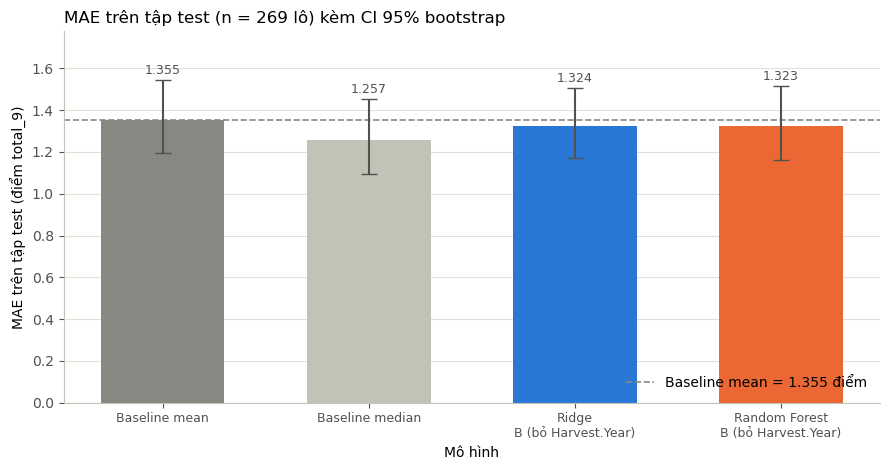

In [26]:
mae_ci = {name: np.percentile(boot_mae[name], [2.5, 97.5]) for name in eval_models}
names = list(eval_models)
heights = [test_mae[n] for n in names]
yerr = np.array([[test_mae[n] - mae_ci[n][0] for n in names], [mae_ci[n][1] - test_mae[n] for n in names]])

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(names, heights, color=[FAMILY_COLORS[n] for n in names], width=0.6, zorder=2)
ax.errorbar(names, heights, yerr=yerr, fmt="none", ecolor=INK_SECONDARY, capsize=6, elinewidth=1.5, zorder=3)
ax.axhline(test_mae["Baseline mean"], color=FAMILY_COLORS["Baseline mean"], linestyle="--", linewidth=1.2,
           label=f"Baseline mean = {test_mae['Baseline mean']:.3f} điểm", zorder=1)
for bar, n in zip(bars, names):
    ax.annotate(f"{test_mae[n]:.3f}", (bar.get_x() + bar.get_width() / 2, mae_ci[n][1]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK_SECONDARY)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n if eval_variant[n] == "—" else f"{n}\n{eval_variant[n]}" for n in names], fontsize=9)
ax.set_ylim(0, max(ci[1] for ci in mae_ci.values()) * 1.15)
ax.set_title(f"MAE trên tập test (n = {len(y_test)} lô) kèm CI 95% bootstrap", loc="left", fontsize=12)
ax.set_xlabel("Mô hình")
ax.set_ylabel("MAE trên tập test (điểm total_9)")
ax.legend(frameon=False, loc="lower right")
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

#### <span style="color:#3B5BA9">Điểm dự đoán và điểm thật của mô hình được chọn</span>

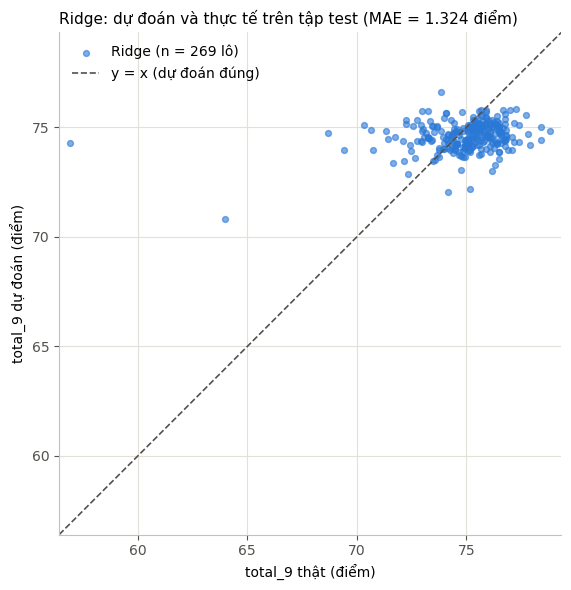

In [27]:
pred_best = test_preds[BEST_NAME]
lims = [min(y_test.min(), pred_best.min()) - 0.5, max(y_test.max(), pred_best.max()) + 0.5]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred_best, s=18, alpha=0.6, color=FAMILY_COLORS[BEST_NAME], label=f"{BEST_NAME} (n = {len(y_test)} lô)")
ax.plot(lims, lims, linestyle="--", color=INK_SECONDARY, linewidth=1.2, label="y = x (dự đoán đúng)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_title(f"{BEST_NAME}: dự đoán và thực tế trên tập test (MAE = {test_mae[BEST_NAME]:.3f} điểm)",
             loc="left", fontsize=11)
ax.set_xlabel("total_9 thật (điểm)")
ax.set_ylabel("total_9 dự đoán (điểm)")
ax.legend(frameon=False, loc="upper left")
style_axes(ax, grid_axis="both")
fig.tight_layout()
plt.show()

> ⚠️ Kết quả test ở trên là lần đánh giá duy nhất. Sau ô này không chỉnh tham số, feature hay mô hình.

✍️ **TODO (Hoàng tự viết):** nhận xét kết quả test — MAE bao nhiêu điểm, so với 2 baseline, CI có chứa 0 không, so với kết quả CV.

<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 6</span>

## <span style="color:#ffffff">Phân tích lỗi</span>

<span style="font-size:15px;color:#DCE6F7">Mô hình sai ở đâu</span>

</div>

<span style="color:#5B6B8C;font-size:14px">Dùng mô hình <code>BEST_NAME</code>. <code>err</code> lấy từ <code>test_df</code> theo đúng thứ tự dòng của tập test; <code>abs_err_baseline</code> là sai số của Baseline mean trên cùng lô. Đơn vị sai số: điểm <code>total_9</code>.</span>

In [28]:
ERR_COLS = ["REC_ID", "Country.of.Origin", "Continent.of.Origin", "Processing.Method", "grading_date"]
err = test_df[ERR_COLS].reset_index(drop=True).assign(
    y=y_test,
    pred=test_preds[BEST_NAME],
    abs_err=abs_errors[BEST_NAME],
    abs_err_baseline=abs_errors["Baseline mean"],
)
print(f"Mô hình: {BEST_NAME} · {len(err)} lô test")
display(err.head())

Mô hình: Ridge · 269 lô test


,REC_ID,Country.of.Origin,Continent.of.Origin,Processing.Method,grading_date,y,pred,abs_err,abs_err_baseline
0,421,brazil,south america,<NA>,2016-01-12,75.26,74.946337,0.313663,0.659337
1,681,brazil,south america,<NA>,2016-01-12,74.42,75.186159,0.766159,0.180663
2,564,vietnam,asia,other,2016-01-19,74.92,74.007440,0.912560,0.319337
3,264,colombia,south america,<NA>,2016-01-21,76.33,74.721272,1.608728,1.729337
4,876,colombia,south america,<NA>,2016-01-21,74.00,75.428994,1.428994,0.600663


### <span style="color:#283E75">▍6a · MAE theo châu lục</span>

In [29]:
err_by_continent = (
    err.groupby("Continent.of.Origin", dropna=False)
    .agg(n=("y", "size"), MAE_model=("abs_err", "mean"), MAE_baseline=("abs_err_baseline", "mean"))
    .sort_values("n", ascending=False)
)
err_by_continent["n < 10"] = err_by_continent["n"].lt(10)
display(err_by_continent.rename(columns={"MAE_model": f"MAE {BEST_NAME} (điểm)",
                                         "MAE_baseline": "MAE baseline mean (điểm)"}).round(3))

,n,MAE Ridge (điểm),MAE baseline mean (điểm),n < 10
Continent.of.Origin,,,,
north america,118,1.405,1.303,False
south america,74,1.053,1.277,False
asia,52,1.558,1.537,False
africa,25,1.254,1.451,False


### <span style="color:#283E75">▍6b · MAE theo 3 nhóm điểm thật</span>

<span style="color:#5B6B8C;font-size:14px"><code>pd.qcut(y, 3)</code>: 3 nhóm có số lô gần bằng nhau. Sai số có dấu = <code>pred − y</code>; dương là mô hình đoán cao hơn thực tế.</span>

In [30]:
err["Nhóm điểm thật"] = pd.qcut(err["y"], 3, labels=["thấp", "giữa", "cao"])
err_by_band = err.groupby("Nhóm điểm thật", observed=True).agg(
    y_min=("y", "min"), y_max=("y", "max"), n=("y", "size"),
    MAE_model=("abs_err", "mean"), MAE_baseline=("abs_err_baseline", "mean"),
    signed_err=("pred", lambda p: (p - err.loc[p.index, "y"]).mean()),
)
err_by_band.insert(0, "Khoảng điểm thật", [f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(err_by_band["y_min"], err_by_band["y_max"])])
display(err_by_band.drop(columns=["y_min", "y_max"]).rename(columns={
    "MAE_model": f"MAE {BEST_NAME} (điểm)", "MAE_baseline": "MAE baseline mean (điểm)",
    "signed_err": "Sai số TB có dấu pred − y (điểm)",
}).round(3))

,Khoảng điểm thật,n,MAE Ridge (điểm),MAE baseline mean (điểm),Sai số TB có dấu pred − y (điểm)
Nhóm điểm thật,,,,,
thấp,56.91–74.67,90,1.521,1.489,1.342
giữa,74.68–75.75,90,0.699,0.672,-0.664
cao,75.76–78.84,89,1.755,1.911,-1.755


### <span style="color:#283E75">▍6c · MAE theo năm chấm</span>

In [31]:
err_by_year = (
    err.assign(**{"Năm chấm": err["grading_date"].dt.year})
    .groupby("Năm chấm")
    .agg(n=("y", "size"), MAE_model=("abs_err", "mean"), MAE_baseline=("abs_err_baseline", "mean"))
)
display(err_by_year.rename(columns={"MAE_model": f"MAE {BEST_NAME} (điểm)",
                                    "MAE_baseline": "MAE baseline mean (điểm)"}).round(3))

,n,MAE Ridge (điểm),MAE baseline mean (điểm)
Năm chấm,,,
2016,123,1.260,1.248
2017,140,1.394,1.456
2018,6,0.991,1.186


### <span style="color:#283E75">▍6d · 10 lô có sai số lớn nhất</span>

In [32]:
top_errors = err.nlargest(10, "abs_err")[ERR_COLS + ["y", "pred", "abs_err", "abs_err_baseline"]]
display(top_errors.round(2))

,REC_ID,Country.of.Origin,Continent.of.Origin,Processing.Method,grading_date,y,pred,abs_err,abs_err_baseline
187,1308,nicaragua,north america,other,2017-06-06,56.91,74.30,17.39,17.69
253,1302,brazil,south america,natural / dry,2017-10-27,63.99,70.81,6.82,10.61
252,1273,brazil,south america,natural / dry,2017-10-27,68.67,74.74,6.07,5.93
251,1253,brazil,south america,natural / dry,2017-10-20,70.33,75.10,4.77,4.27
125,1260,india,asia,natural / dry,2017-01-16,69.43,73.99,4.56,5.17
18,1246,nicaragua,north america,<NA>,2016-02-29,70.67,74.90,4.23,3.93
42,18,china,asia,washed / wet,2016-04-07,78.84,74.85,3.99,4.24
168,28,honduras,north america,<NA>,2017-05-18,78.41,74.44,3.97,3.81
57,52,guatemala,north america,washed / wet,2016-05-16,77.91,74.18,3.73,3.31
206,1233,indonesia,asia,washed / wet,2017-07-18,71.34,74.83,3.49,3.26


#### <span style="color:#3B5BA9">Results 2 · MAE theo châu lục: mô hình và baseline</span>

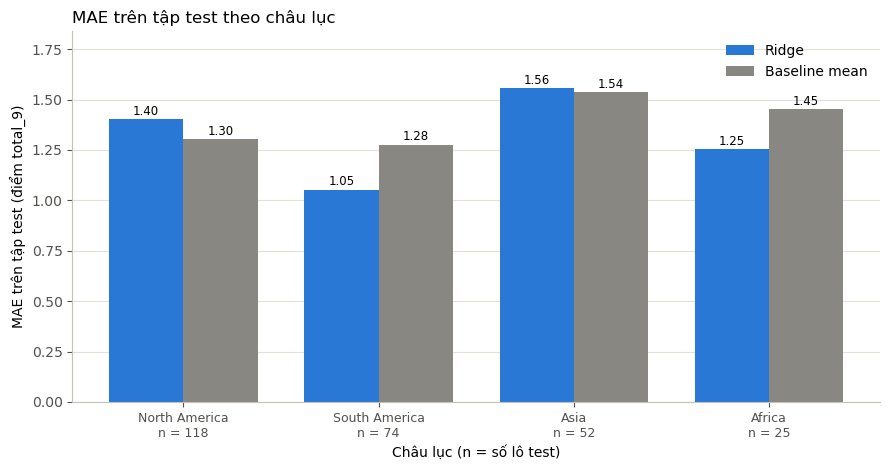

In [33]:
cont = err_by_continent.reset_index()
cont_labels = [f"{str(c).title() if pd.notna(c) else 'Thiếu'}\nn = {n}" for c, n in zip(cont["Continent.of.Origin"], cont["n"])]
x = np.arange(len(cont))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(x - width / 2, cont["MAE_model"], width, color=FAMILY_COLORS[BEST_NAME], label=BEST_NAME, zorder=2)
ax.bar(x + width / 2, cont["MAE_baseline"], width, color=FAMILY_COLORS["Baseline mean"], label="Baseline mean", zorder=2)
for xi, (m, b) in enumerate(zip(cont["MAE_model"], cont["MAE_baseline"])):
    ax.annotate(f"{m:.2f}", (xi - width / 2, m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
    ax.annotate(f"{b:.2f}", (xi + width / 2, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(cont_labels, fontsize=9)
ax.set_ylim(0, max(cont["MAE_model"].max(), cont["MAE_baseline"].max()) * 1.18)
ax.set_title("MAE trên tập test theo châu lục", loc="left", fontsize=12)
ax.set_xlabel("Châu lục (n = số lô test)")
ax.set_ylabel("MAE trên tập test (điểm total_9)")
ax.legend(frameon=False)
style_axes(ax, grid_axis="y")
fig.tight_layout()
plt.show()

✍️ **TODO (Hoàng tự viết):** kết luận phân tích lỗi theo dạng "mô hình đáng tin cho …, sai nhiều ở …, không nên dùng cho …".

In [34]:
# TEST
assert err_by_continent["n"].sum() == len(X_test) == len(err), "Tổng n theo châu lục phải bằng số lô test"
assert np.isclose(err["abs_err"].mean(), test_mae[BEST_NAME]), "MAE tính lại từ err khác bảng 5a"
assert np.isclose(err["abs_err_baseline"].mean(), test_mae["Baseline mean"]), "MAE baseline tính lại khác bảng 5a"
assert err_by_band["n"].sum() == len(err), "Tổng n theo nhóm điểm phải bằng số lô test"
assert len(top_errors) == 10, f"Bảng sai số lớn nhất phải có 10 dòng, đang có {len(top_errors)}"
print("Q2 error analysis checks passed")

Q2 error analysis checks passed


<div style="background-color:#283E75;color:#ffffff;padding:14px 24px;border-radius:8px;margin-top:24px">

<span style="font-size:17px;font-weight:700;letter-spacing:3px;color:#E3EBFA">PHẦN 7</span>

## <span style="color:#ffffff">Diễn giải mô hình và trả lời Q2</span>

<span style="font-size:15px;color:#DCE6F7">Permutation importance trên tập test</span>

</div>

### <span style="color:#283E75">▍7a · Permutation importance</span>

<span style="color:#5B6B8C;font-size:14px">Xáo trộn từng <b>cột feature gốc</b> (trước one-hot) trên tập test, 10 lần mỗi cột. Giá trị = MAE sau khi xáo trộn − MAE gốc, đơn vị điểm <code>total_9</code>; càng lớn, mô hình càng dựa vào cột đó để dự đoán.</span>

In [35]:
X_test_best = X_test[final_features[BEST_NAME]]
perm = permutation_importance(final_models[BEST_NAME], X_test_best, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
importance_table = (
    pd.DataFrame({"Feature": X_test_best.columns,
                  "Mức tăng MAE mean (điểm)": perm.importances_mean,
                  "Mức tăng MAE std (điểm)": perm.importances_std})
    .sort_values("Mức tăng MAE mean (điểm)", ascending=False)
    .reset_index(drop=True)
)
display(importance_table.assign(**{
    "Mức tăng MAE khi xáo trộn (điểm)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(importance_table["Mức tăng MAE mean (điểm)"],
                                                                            importance_table["Mức tăng MAE std (điểm)"])]
})[["Feature", "Mức tăng MAE khi xáo trộn (điểm)"]])

,Feature,Mức tăng MAE khi xáo trộn (điểm)
0,Continent.of.Origin,0.048 ± 0.019
1,Category.Two.Defects,0.030 ± 0.011
2,Variety,0.030 ± 0.009
3,Country.of.Origin,0.018 ± 0.008
4,Quakers,0.008 ± 0.008
5,Moisture,0.001 ± 0.002
6,Color,0.000 ± 0.004
7,Category.One.Defects,0.000 ± 0.006
8,Processing.Method,-0.006 ± 0.006


#### <span style="color:#3B5BA9">Biểu đồ permutation importance</span>

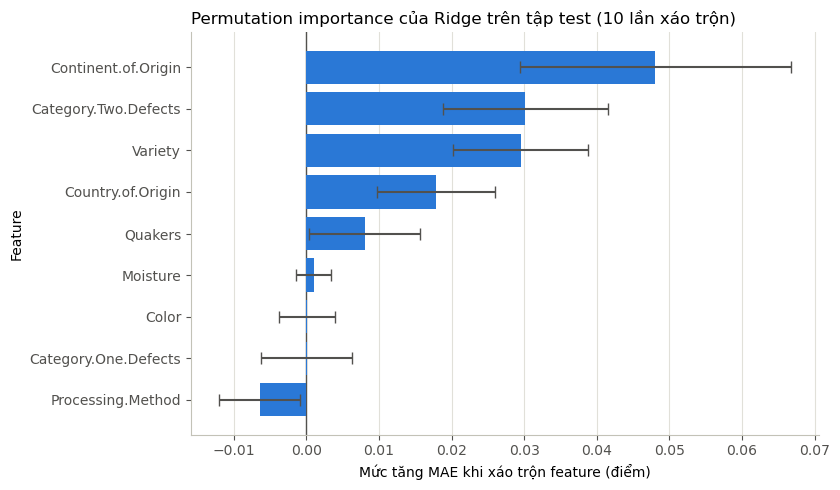

In [36]:
plot_imp = importance_table.iloc[::-1]   # lớn nhất ở trên cùng
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(plot_imp["Feature"], plot_imp["Mức tăng MAE mean (điểm)"], xerr=plot_imp["Mức tăng MAE std (điểm)"],
        color=FAMILY_COLORS[BEST_NAME], ecolor=INK_SECONDARY, capsize=4, zorder=2)
ax.axvline(0, color=INK_SECONDARY, linewidth=1, zorder=1)
ax.set_title(f"Permutation importance của {BEST_NAME} trên tập test (10 lần xáo trộn)", loc="left", fontsize=12)
ax.set_xlabel("Mức tăng MAE khi xáo trộn feature (điểm)")
ax.set_ylabel("Feature")
style_axes(ax, grid_axis="x")
fig.tight_layout()
plt.show()

### <span style="color:#283E75">▍Trả lời câu hỏi Q2</span>

✍️ **TODO (Hoàng tự viết):** đọc permutation importance — feature nào có ích, feature nào gần 0 hoặc âm; độ quan trọng là sức mạnh dự đoán, không phải nhân quả.

✍️ **TODO (Hoàng tự viết):** trả lời Q2 đủ 3 vế — sai lệch trung bình bao nhiêu điểm; có tốt hơn đáng kể so với đoán trung bình không (dẫn CI ở 5b); thông tin nào giúp nhiều nhất.

✍️ **TODO (Hoàng tự viết):** mô hình dùng được trong phạm vi nào, không dùng được ở đâu (theo PHẦN 6); ý nghĩa cho nhà nhập khẩu.

✍️ **TODO (Hoàng tự viết):** hạn chế — giả định grading_date = Expiration − 365 ngày, dữ liệu 2010–2018, chỉ lô gửi CQI, feature có nhiều giá trị thiếu; điều bất ngờ nếu có.

In [37]:
# TEST
assert len(importance_table) == X_test_best.shape[1], (
    f"Bảng importance có {len(importance_table)} dòng, X_test_best có {X_test_best.shape[1]} cột"
)
assert not importance_table.isna().any().any(), "Bảng importance có NaN"
print("Q2 interpretation checks passed")

Q2 interpretation checks passed
